In [1]:
import os
import sys

# sys.path.append(os.path.expanduser("~/repos/cax-scripts"))
sys.path.append(os.path.expanduser("~/scripts"))
# sys.path.append(os.path.expanduser("~/repos/cax-control"))
import matplotlib.pyplot as plt

# from Shadow import histo
import numpy as np
from shadowpy.si_beamlines import CAXSim
from shadowpy.utils import save_image, Image

from image_statistics import Histogram2DAnalyzer


No module named 'xraylib'


In [16]:
cax = CAXSim(total_rays=500000, image_size=(100, 100))


 Generated        25000  rays out of       500000
                  50000
                  75000
                 100000
                 125000
                 150000
                 175000
                 200000
                 225000
                 250000
                 275000
                 300000
                 325000
                 350000
                 375000
                 400000
                 425000
                 450000
                 475000
                 500000
 Exit from SOURCE
 Call to RESET
Traced through element 1: MASK_A1
 Exit from RESET
 Call to SETSOUR
 Exit from SETSOUR
 Call to IMREF
 Exit from IMREF
 Call to OPTAXIS
 Exit from OPTAXIS
 Call to MSETUP
 Exit from MSETUP
 Call to RESTART
 Exit from RESTART
 Call to MIRROR
 MIRROR1: Warning: Empty element (no mirr.xx file)
 Call to SCREEN
 Exit from SCREEN
 Call to IMAGE
 Exit from IMAGE
 Call to DEALLOC
 Exit from DEALLOC
 Call to RESET
 Exit from RESET
 Call to SETSOUR
 Exit from SETSOUR

In [17]:
def ana_from_image(image: Image):

    ana = Histogram2DAnalyzer(
        img=image.histogram,
        x_bin_edges=image.bin_h_edges*1000,
        y_bin_edges=image.bin_v_edges*1000
    )

    return ana

In [23]:
cax.mirror.tx = 0

In [24]:
ana = ana_from_image(cax.dvf_B1.image)
ana.fit(hprm=ana.compute_momenta())

 Call to RESET
 Exit from RESET
 Call to SETSOUR
 Exit from SETSOUR
 Call to IMREF
 Exit from IMREF
 Call to OPTAXIS
Traced through element 2: M1
 Exit from OPTAXIS
 Call to MSETUP
 Exit from MSETUP
 Call to RESTART
 Exit from RESTART
 Call to MIRROR
 Exit from MIRROR
 Call to IMAGE
 Exit from IMAGE
 Call to DEALLOC
 Exit from DEALLOC
 Call to RESET
 Exit from RESET
 Call to SETSOUR
 Exit from SETSOUR
 Call to IMREF
 Exit from IMREF
 Call to OPTAXIS
 Exit from OPTAXIS
 Call to MSETUP
 Exit from MSETUP
 Call to RESTART
 Exit from RESTART
 Call to MIRROR
 MIRROR1: Warning: Empty element (no mirr.xx file)
 Call to SCREEN
 Exit from SCREEN
 Call to IMAGE
 Exit from IMAGE
 Call to DEALLOC
 Exit from DEALLOC
Traced through element 3: DVF_A1
 Call to RESET
 Exit from RESET
Traced through element 4: DVF_B1
 Call to SETSOUR
 Exit from SETSOUR
 Call to IMREF
 Exit from IMREF
 Call to OPTAXIS
 Exit from OPTAXIS
 Call to MSETUP
 Exit from MSETUP
 Call to RESTART
 Exit from RESTART
 Call to MIRROR


{'mux': 0.13630926723663764,
 'muy': 0.06182810885278242,
 'sigx': 20.34045210340454,
 'sigy': 11.798522469633506,
 'fwhmx': 47.89810433808895,
 'fwhmy': 27.783397213241038,
 'cov': array([[413.73399177,   0.87294684],
        [  0.87294684, 139.20513247]]),
 'sig_major': 20.34052033599626,
 'sig_minor': 11.798404837021971,
 'theta': 0.0031797570191436364,
 'evecs': array([[-0.99999494,  0.00317975],
        [-0.00317975, -0.99999494]]),
 'amplitude': 87.12247975147535,
 'threshold': -0.010864162077936253,
 'x_bin_centers': array([-86.3744377 , -84.62488979, -82.87534189, -81.12579398,
        -79.37624608, -77.62669817, -75.87715027, -74.12760236,
        -72.37805445, -70.62850655, -68.87895864, -67.12941074,
        -65.37986283, -63.63031492, -61.88076702, -60.13121911,
        -58.38167121, -56.6321233 , -54.88257539, -53.13302749,
        -51.38347958, -49.63393168, -47.88438377, -46.13483587,
        -44.38528796, -42.63574005, -40.88619215, -39.13664424,
        -37.38709634, -

(<Figure size 1000x600 with 2 Axes>,
 <Axes: title={'center': '2D Histogram with Ellipses'}, xlabel='x', ylabel='y'>)

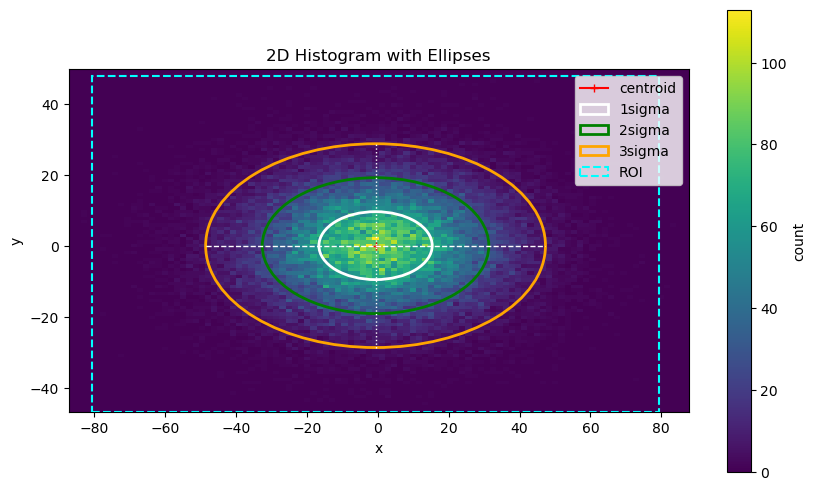

In [25]:
ana.plot(hprm=ana.hprm_project, roi_zoom=None)

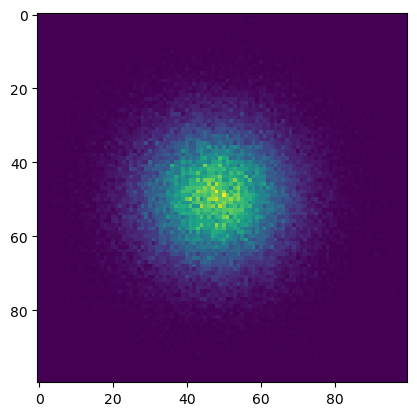

In [26]:
plt.imshow(ana.img)

In [31]:
cxs = []
txs  = np.linspace(-2, 2, 31)
for _tx in txs:
    cax.mirror.tx = _tx
    ana = ana_from_image(cax.dvf_B1.image)
    ana.compute_momenta()

    cxs.append(ana.hprm_momenta['mux'])


[print(f"Cx = {mux:+.2f} μm") for mux in cxs]
    

 Call to RESET
 Exit from RESET
 Call to SETSOUR
 Exit from SETSOUR
 Call to IMREF
 Exit from IMREF
 Call to OPTAXIS
 Exit from OPTAXIS
 Call to MSETUP
 Exit from MSETUP
 Call to RESTART
 Exit from RESTART
 Call to MIRROR
 Exit from MIRROR
 Call to IMAGE
 Exit from IMAGE
 Call to DEALLOC
 Exit from DEALLOC
Traced through element 2: M1
 Call to RESET
 Exit from RESET
 Call to SETSOUR
 Exit from SETSOUR
 Call to IMREF
 Exit from IMREF
 Call to OPTAXIS
Traced through element 3: DVF_A1
 Exit from OPTAXIS
 Call to MSETUP
 Exit from MSETUP
 Call to RESTART
 Exit from RESTART
 Call to MIRROR
 MIRROR1: Warning: Empty element (no mirr.xx file)
 Call to SCREEN
 Exit from SCREEN
 Call to IMAGE
 Exit from IMAGE
 Call to DEALLOC
 Exit from DEALLOC
 Call to RESET
 Exit from RESET
 Call to SETSOUR
 Exit from SETSOUR
 Call to IMREF
 Exit from IMREF
 Call to OPTAXIS
 Exit from OPTAXIS
 Call to MSETUP
 Exit from MSETUP
 Call to RESTART
 Exit from RESTART
 Call to MIRROR
 MIRROR1: Warning: Empty element 

[None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None]

Text(0, 0.5, 'Centroid x [μm]')

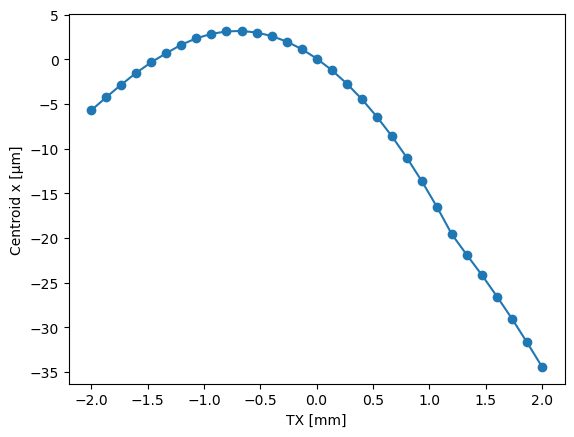

In [33]:
plt.plot(txs, cxs, marker='o')
plt.xlabel('TX [mm]')
plt.ylabel('Centroid x [μm]')


In [4]:
cax.dvf_A1.shadow_oe.RX_SLIT[0] = 1.0
cax.dvf_A1.shadow_oe.RZ_SLIT[0] = 1.0



In [14]:
print(f"ΔTX = {np.ptp(txs):.2f} mm")
print(f"ΔCx = {np.ptp(cxs)*0.48:.2f} μm")

ΔTX = 1.00 mm
ΔCx = 6.93 μm


In [27]:
cax.mirror.offset# = np.random.normal(0, 1/2, 3)
cax.mirror.tilt = np.random.normal(0, 0.0001, 3)
cax.mirror.tilt

array([0.00215555, 0.00218167, 0.00937586])

In [ ]:
ana_source = cax.source.image

fig, ax = plt.subplots(figsize=(10, 6))
fig, ax = ana_source.plot( fig=fig, ax=ax )
ax.set_xlabel("x [mm]")
ax.set_ylabel("y [mm]")
ax.set_title("Image at source ($z = 0$ m)")

In [ ]:
cax.mirror.ry = 0.1

In [ ]:
cax.dvf_B1.image.plot()

In [ ]:
# Propagated
source_beam = cax.beams[0].duplicate()
source_beam.retrace(17000) #17 m
ana_at_mirror = save_image(cax.source, source_beam)

In [ ]:
fig, ax = plt.subplots(figsize=(10, 6))
m = ax.pcolormesh(
            ana_at_mirror.x_bin_edges, ana_at_mirror.y_bin_edges, ana_at_mirror.img.T,
            shading="auto", cmap="viridis",
        )
ax.set_xlabel("x [mm]")
ax.set_ylabel("y [mm]")
plt.colorbar(m, ax=ax, label="count")
ax.set_title("Image before mirror ($z = 17^-$ m)")
plt.show()

In [ ]:
image_ticket.keys()

In [ ]:
mirror_beam = cax.mirror.beam.duplicate()

image_ticket = mirror_beam.histo2(col_h=2, col_v=1, 
                                   nbins_h=280, nbins_v=210, 
                                   nolost=1)

histogram   = image_ticket["histogram"]
bin_h_centers = image_ticket["bin_h_center"]
bin_v_centers = image_ticket["bin_v_center"]

fig, ax = plt.subplots(figsize=(7, 6))
m = ax.pcolormesh(
            bin_h_centers, bin_v_centers, histogram.T,
            shading="auto", cmap="viridis",
        )
ax.set_xlabel("z [mm]")
ax.set_ylabel("y [mm]")
plt.colorbar(m, ax=ax, label="count")
ax.set_title("Beam along the mirror surface")
plt.show()

In [ ]:
# Propagated
mirror_beam = cax.mirror.beam.duplicate()
# source_beam.retrace(17000) #17 m
ana_after_mirror = save_image(cax.mirror, mirror_beam)

In [ ]:
fig, ax = plt.subplots(figsize=(7.5, 6))
m = ax.pcolormesh(
            ana_after_mirror.x_bin_edges, ana_after_mirror.y_bin_edges, ana_after_mirror.img.T,
            shading="auto", cmap="viridis",
        )
ax.set_xlabel("x [mm]")
ax.set_ylabel("y [mm]")
plt.colorbar(m, ax=ax, label="count")
ax.set_title("Image after mirror ($z = 17^+$ m)")
plt.show()

In [ ]:
cax.dvf_A1.source_distance

In [ ]:
# Propagated
slit_beam = cax.mirror.beam.duplicate()
slit_beam.retrace(4359)
# source_beam.retrace(17000) #17 m
ana_before_slit = save_image(cax.dvf_A1, slit_beam)

In [ ]:
fig, ax = plt.subplots(figsize=(7, 6))
m = ax.pcolormesh(
            ana_before_slit.x_bin_edges, ana_before_slit.y_bin_edges, ana_before_slit.img.T,
            shading="auto", cmap="viridis",
        )
ax.set_xlabel("x [mm]")
ax.set_ylabel("y [mm]")
plt.colorbar(m, ax=ax, label="count")
ax.set_title("Image before slit ($z = 21.359$ m)")
plt.show()

In [ ]:
cax.mirror.ry = -0.1

In [ ]:
fig, ax = plt.subplots(figsize=(10, 6))
fig, ax = cax.dvf_B1.image.plot(fig=fig, ax=ax)
ax.set_xlabel("x [mm]")
ax.set_ylabel("y [mm]")
ax.set_title("Image at screen ($z = 34$ m)")

In [ ]:
cx = cax.dvf_B1.image.hprm_project['mux']
cy = cax.dvf_B1.image.hprm_project['muy']
# cx, cy = cy, cx

fx = cax.dvf_B1.image.hprm_project['fwhmx']
fy = cax.dvf_B1.image.hprm_project['fwhmy']

cax.dvf_B1.image.img[cx, cy]
print(cx, cy)
np.unravel_index(cax.dvf_B1.image.img.argmax(), cax.dvf_B1.image.img.shape)


In [ ]:
cax.dvf_B1.image.x_bin_centers[cx]

In [ ]:
cax.dvf_B1.image.qck_intensity(cax.dvf_B1.image.img, (cx, cy), (fx, fy), 1)

In [ ]:
image_ticket = cax.dvf_B1.beam.histo2(col_h=3, col_v=1, 
                            nbins_h=280, nbins_v=210, nolost=1)

In [ ]:
hist = np.array(image_ticket['histogram'])
h_centers = np.array(image_ticket['bin_h_center'])
v_centers = np.array(image_ticket['bin_v_center'])

In [ ]:
cax.dvf_B1.image.plot(hprm=cax.dvf_B1.image.hprm_momenta)

In [ ]:
from optlnls.plot import plot_beam


In [ ]:
x = h_centers
y = v_centers
img = hist

beam2D_2 = np.zeros((len(y)+1, len(x)+1))
beam2D_2[0,1:] = x
beam2D_2[1:,0] = y
beam2D_2[1:,1:] = img.T


plot_beam(beam2D_2, cut=0, textA=1, textB=10, textC=9, textD=0, fitType=1,
          plot_title='CAX M1 nominal', show_colorbar=1,
            x_range=1, y_range=1, x_range_min=-0.12, x_range_max=0.12, y_range_min=-0.12, y_range_max=0.12,
          zero_pad_x=1, zero_pad_y=1, cmap='viridis', integral=1e11,
          units=2)


In [ ]:
x = cax.dvf_B1.image.x_bin_centers
y = cax.dvf_B1.image.y_bin_centers
img = cax.dvf_B1.image.img

beam2D = np.zeros((len(y)+1, len(x)+1))
beam2D[0,1:] = x
beam2D[1:,0] = y
beam2D[1:,1:] = img.T


plot_beam(beam2D, cut=0, textA=1, textB=10, textC=3, textD=0, fitType=1,
          plot_title='CAX M1 nominal', show_colorbar=1,
            x_range=1, y_range=1, x_range_min=-0.12, x_range_max=0.12, y_range_min=-0.12, y_range_max=0.12,
          zero_pad_x=1, zero_pad_y=1, cmap='viridis', integral=1e11,
          units=2)


In [ ]:
print(cax.dvf_B1.image.hprm_fitting['mux']*1000)
print(cax.dvf_B1.image.hprm_fitting['muy']*1000)

In [ ]:
cax.dvf_B1.image.print_stats(cax.dvf_B1.image.hprm_fitting)

In [ ]:
cax.dvf_B1.image.img.shape